<a href="https://colab.research.google.com/github/Yxiru/testttt/blob/main/CRM_CW_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6BUIS017W CRM Coursework 1: Market Analysis and Stock Segmentation Using RFM

**How to run**
1. First run: set `USE_CACHE = False` in the Setup cell, then *Runtime → Restart session* and run every cell down to "Save the live-run reference". This downloads the data once and saves `data/sp500_data.pkl`.
2. Second run: set `USE_CACHE = True`, restart, run every cell again, then run the reproducibility check. Nothing is downloaded; everything loads from the snapshot.
3. Task 2.2 follows the reproducibility check.

## Mount Google Drive
All snapshots and outputs are written to `MyDrive/CRM_CW1` so they persist between Colab sessions.

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/CRM_CW1', exist_ok=True)
%cd /content/drive/MyDrive/CRM_CW1

### One-off cleanup (run once before the first run, then delete this cell)
Removes the earlier CSV-format snapshot so it cannot be mixed with the new pickle snapshot.

In [ ]:
import glob
for f in glob.glob('data/daily_*.csv.gz') + glob.glob('data/sp500_changes.csv'):
    os.remove(f); print('removed', f)

## Setup

In [1]:
# ===== 0. Setup =====
USE_CACHE = False        # False = download once and save; True = load data/sp500_data.pkl (no download)

if not USE_CACHE:
    !pip install -q --upgrade yfinance

import os, json, time, datetime, platform
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy

DATA_DIR = 'data'        # raw snapshots (committed to GitHub)
OUT_DIR = 'outputs'      # feature tables, clusters, figures
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

versions = {'python': platform.python_version(), 'pandas': pd.__version__,
            'numpy': np.__version__, 'yfinance': yf.__version__,
            'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__,
            'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}
print(pd.Series(versions).to_string())

python          3.13.18
pandas            2.2.3
numpy             2.4.6
yfinance          1.8.0
matplotlib       3.10.0
seaborn          0.13.2
scikit-learn      1.6.1
scipy            1.16.3


# Task 1: Data Preparation and Feature Engineering

## 1.1 Ticker selection and data acquisition

In [2]:
# ===== 1.1(a) S&P 500 constituents from Wikipedia (Week 4, cell 2) =====
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
changes = None

if USE_CACHE:
    sp500_df = pd.read_csv(f'{DATA_DIR}/sp500_constituents.csv')
    meta = json.load(open(f'{DATA_DIR}/metadata.json'))
    ticker_retrieved_utc = meta['ticker_retrieved_utc']
    if os.path.exists(f'{DATA_DIR}/sp500_changes.csv'):
        changes = pd.read_csv(f'{DATA_DIR}/sp500_changes.csv')
else:
    # User-Agent is required to avoid HTTP 403 blocking from Wikipedia
    table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
    ticker_retrieved_utc = datetime.datetime.now(datetime.timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
    sp500_df = table[0].copy()
    # BRK.B -> BRK-B (Yahoo Finance convention)
    sp500_df['Yahoo_Symbol'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
    sp500_df.to_csv(f'{DATA_DIR}/sp500_constituents.csv', index=False)

    # Find the index-changes table by its columns, not by position (page layout can change)
    for t in table[1:]:
        cols = ['_'.join(map(str, c)) if isinstance(c, tuple) else str(c) for c in t.columns]
        if any('Added' in c for c in cols) and any('Removed' in c for c in cols):
            changes = t.copy()
            changes.columns = cols
            changes.to_csv(f'{DATA_DIR}/sp500_changes.csv', index=False)
            break
    if changes is None:
        print('Index-changes table not found on the page; tables found:', len(table))

# Basic acquisition checks
assert len(sp500_df) > 0, 'Constituent list is empty'
assert {'Symbol', 'Security', 'GICS Sector', 'Date added'}.issubset(sp500_df.columns), 'Expected columns missing'
assert sp500_df['Yahoo_Symbol'].is_unique, 'Duplicate ticker symbols'

tickers = sp500_df['Yahoo_Symbol'].tolist()

print('Ticker list retrieved:', ticker_retrieved_utc)
print('Total tickers extracted:', len(tickers))
print('\nShares per GICS sector:')
print(sp500_df['GICS Sector'].value_counts().to_string())

# --- Survivorship-bias evidence (runs in both live and cache mode) ---
sp500_df['Date_added_parsed'] = pd.to_datetime(sp500_df['Date added'], errors='coerce')
added_late = sp500_df[sp500_df['Date_added_parsed'] >= '2021-01-01']
print('\nCurrent constituents added to the index on/after 1 Jan 2021:', len(added_late),
      f'({len(added_late) / len(sp500_df) * 100:.1f}%)')

if changes is not None:
    try:
        date_col = [c for c in changes.columns if 'Date' in c][0]
        removed_col = [c for c in changes.columns if c.startswith('Removed') and 'Ticker' in c][0]
        effective = pd.to_datetime(changes[date_col], errors='coerce')
        in_period = changes[(effective >= '2021-01-01') & (effective < '2025-01-01')]
        removed = (in_period[removed_col].dropna().astype(str).str.strip()
                   .str.replace('.', '-', regex=False))
        removed_unique = set(removed)
        absent_now = sorted(removed_unique - set(tickers))
        # Note: a ticker symbol can occasionally be reused by a different company later
        print('Index change rows dated in the study period:', len(in_period))
        print('Removal events in the study period:', len(removed))
        print('Unique tickers removed in the study period:', len(removed_unique))
        print('...of which absent from the current list:', len(absent_now))
    except Exception as e:
        print('Changes table could not be parsed:', e, '| columns:', list(changes.columns)[:6])

Index-changes table not found on the page; tables found: 2
Ticker list retrieved: 2026-11-22 13:44 UTC
Total tickers extracted: 503

Shares per GICS sector:
GICS Sector
Industrials               83
Information Technology    76
Financials                76
Health Care               60
Consumer Discretionary    47
Consumer Staples          33
Utilities                 31
Real Estate               30
Materials                 24
Communication Services    22
Energy                    21

Current constituents added to the index on/after 1 Jan 2021: 89 (17.7%)


In [3]:
# ===== 1.1(b) Daily prices, adjusted prices, volume and corporate actions (Week 4 pickle approach) =====
start = '2021-01-01'
end = '2025-01-01'          # yfinance end date is exclusive -> last possible day 31 Dec 2024
fields = ['Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']
PKL_PATH = f'{DATA_DIR}/sp500_data.pkl'
LOG_COLS = ['Share', 'Stage', 'Reason', 'Yahoo_message']

def no_price_tickers(data):
    """Tickers with neither Close nor Adj Close anywhere in the period."""
    empty = data['Adj Close'].isna().all() & data['Close'].isna().all()
    return empty[empty].index.tolist()

if USE_CACHE:
    # Read from the saved pickle file (Week 4 tutorial) instead of downloading again
    sp500_data = pd.read_pickle(PKL_PATH)
    acq_log = pd.read_csv(f'{DATA_DIR}/acquisition_log.csv')
    price_retrieved_utc = meta['price_retrieved_utc']
else:
    # Include the ^GSPC benchmark with the tickers (Week 4 tutorial)
    tickers_with_benchmark = tickers + ['^GSPC']
    sp500_data = yf.download(tickers_with_benchmark, start=start, end=end,
                             auto_adjust=False, actions=True)
    price_retrieved_utc = datetime.datetime.now(datetime.timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
    first_errors = dict(getattr(getattr(yf, 'shared', None), '_ERRORS', {}))   # diagnostic only

    missing_fields = [f for f in fields if f not in sp500_data.columns.get_level_values(0)]
    assert not missing_fields, f'Fields missing from download: {missing_fields}'

    # Retry empty tickers once: a rate-limit failure is not the same as "no data exists"
    failed = no_price_tickers({f: sp500_data[f].reindex(columns=tickers) for f in fields})
    retry_errors = {}
    if failed:
        print(f'Retrying {len(failed)} tickers one at a time...')
        time.sleep(10)
        retry = yf.download(failed, start=start, end=end, auto_adjust=False,
                            actions=True, threads=False)
        retry_errors = dict(getattr(getattr(yf, 'shared', None), '_ERRORS', {}))
        if not retry.empty:
            sp500_data = sp500_data.combine_first(retry).sort_index()   # keeps any new dates

# ===== Derive the variables used by Tasks 1.2-2.1 =====
assert '^GSPC' in sp500_data['Adj Close'].columns, 'Benchmark ^GSPC missing from sp500_data'
data = {f: sp500_data[f].reindex(columns=tickers) for f in fields}
market = pd.DataFrame({f: sp500_data[f]['^GSPC'] for f in ['Close', 'Adj Close', 'Volume']})

if not USE_CACHE:
    # Record failures: state only what was observed; Yahoo's message kept as a diagnostic
    failed = no_price_tickers(data)
    rows = [{'Share': t, 'Stage': '1.1 acquisition',
             'Reason': 'Yahoo Finance returned no historical prices for the required period after one retry',
             'Yahoo_message': str(retry_errors.get(t, first_errors.get(t, '')))[:150]}
            for t in failed]
    acq_log = pd.DataFrame(rows, columns=LOG_COLS)   # explicit columns: safe when empty
    acq_log = acq_log.merge(sp500_df[['Yahoo_Symbol', 'Security', 'Date added']],
                            left_on='Share', right_on='Yahoo_Symbol', how='left'
                            ).drop(columns='Yahoo_Symbol')

# ===== Acquisition checks (run before anything is saved) =====
adj_close = data['Adj Close']
assert adj_close.index.min() >= pd.Timestamp(start), 'Data before study start'
assert adj_close.index.max() < pd.Timestamp(end), 'Data on/after exclusive end date'
assert (adj_close.notna().any() | data['Close'].notna().any()).sum() > 0, 'No valid share data downloaded'
assert market['Adj Close'].notna().any(), 'Benchmark has no prices'
assert market.index.min() >= pd.Timestamp(start) and market.index.max() < pd.Timestamp(end), 'Benchmark dates outside period'

# ===== Save the dataset as a pickle file only after all checks pass =====
if not USE_CACHE:
    sp500_data.to_pickle(PKL_PATH)
    acq_log.to_csv(f'{DATA_DIR}/acquisition_log.csv', index=False)
    print('Saved', PKL_PATH, 'and acquisition_log.csv')

# ===== Summary =====
print('sp500_data:', sp500_data.shape, '| fields:', sorted(set(sp500_data.columns.get_level_values(0))))
print('Price data retrieved:', price_retrieved_utc)
print('Trading days:', len(adj_close),
      '| first:', adj_close.index.min().date(), '| last:', adj_close.index.max().date())
print('Tickers requested:', len(tickers))
print('Tickers with any price data (Close or Adj Close):',
      (adj_close.notna().any() | data['Close'].notna().any()).sum())
print('Tickers with no price data:', len(acq_log))
print('^GSPC rows with prices:', int(market['Adj Close'].notna().sum()), '|',
      market.index.min().date(), 'to', market.index.max().date())

# Exclusion log: later stages append records with the same columns
exclusion_log = acq_log[LOG_COLS].to_dict('records')
print(acq_log.to_string(index=False))

[*****                 11%                       ]  57 of 504 completedERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*****************     35%                       ]  175 of 504 completedERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*******************   39%                       ]  197 of 504 completedERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*******************   40%                       ]  201 of 504 completedERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************52%                       ]  261 of 504 completedERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['VYLR', 'FDXF', 'HONA', 'Q', 'SNDK']: Data doesn't exist for startDat

Retrying 5 tickers one at a time...


ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[                       0%                       ]ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*******************   40%                       ]  2 of 5 completedERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************60%****                   ]  3 of 5 completedERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************80%*************          ]  4 of 5 completedERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*********************100%***********************]  5 of 5 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['VYLR', 'FDXF', 'Q', 'SNDK', 'HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Saved data/sp500_data.pkl and acquisition_log.csv
sp500_data: (1005, 4022) | fields: ['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']
Price data retrieved: 2026-11-22 13:45 UTC
Trading days: 1005 | first: 2021-01-04 | last: 2024-12-31
Tickers requested: 503
Tickers with any price data (Close or Adj Close): 498
Tickers with no price data: 5
^GSPC rows with prices: 1005 | 2021-01-04 to 2024-12-31
Share           Stage                                                                              Reason Yahoo_message            Security Date added
 FDXF 1.1 acquisition Yahoo Finance returned no historical prices for the required period after one retry                     FedEx Freight 2026-06-01
 HONA 1.1 acquisition Yahoo Finance returned no historical prices for the required period after one retry               Honeywell Aerospace 2026-06-29
    Q 1.1 acquisition Yahoo Finance returned no historical prices for the required period after one retry        

In [19]:
# ===== 1.1(c) Display downloaded dataset =====

print("Dataset shape:", sp500_data.shape)
print("Trading days:", len(sp500_data))

print("\nAvailable data fields:")
print(sp500_data.columns.get_level_values(0).unique().tolist())

print("\nSample of the combined historical dataset:")
display(sp500_data.head())

print("\nApple (AAPL) historical data:")
display(sp500_data.xs('AAPL', axis=1, level=1).head(10))

print("\nS&P 500 benchmark data:")
display(market.head(10))

Dataset shape: (1005, 4022)
Trading days: 1005

Available data fields:
['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']

Sample of the combined historical dataset:


Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009117  125.537109  84.219147  139.149994  97.269699   
2021-01-05  114.941254  127.089211  85.090019  148.300003  98.473190   
2021-01-06  118.093239  122.811203  84.354965  142.770004  98.268158   
2021-01-07  121.235596  127.001907  85.257797  151.270004  99.222061   
2021-01-08  122.100464  128.098068  85.705200  149.770004  99.498405   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029297  485.339996  132.622620  42.189487  ...   
2021-01-05  33.319485  233.350266  485.690002  134.993164  43.010094  ...   
2021-01-06  34.783871  235.901627  466.309998  135.601685  44.752834  ...   
2021-01-07  34.460564  238.127289  477.739990  141.332748  44.355221  ...   
2021-01-08  34.650742  238.995865  485.100006  142.359070  44.473660  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 4022 columns]


Apple (AAPL) historical data:


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,
2021-01-04,125.537109,129.410004,0.0,133.610001,126.760002,133.520004,0.0,143301900
2021-01-05,127.089211,131.009995,0.0,131.740005,128.429993,128.889999,0.0,97664900
2021-01-06,122.811203,126.599998,0.0,131.050003,126.379997,127.720001,0.0,155088000
2021-01-07,127.001907,130.919998,0.0,131.630005,127.860001,128.360001,0.0,109578200
2021-01-08,128.098068,132.050003,0.0,132.630005,130.229996,132.429993,0.0,105158200
2021-01-11,125.119957,128.979996,0.0,130.169998,128.500000,129.190002,0.0,100384500
2021-01-12,124.945381,128.800003,0.0,129.690002,126.860001,128.500000,0.0,91951100
2021-01-13,126.972809,130.889999,0.0,131.449997,128.490005,128.759995,0.0,88636800
2021-01-14,125.052071,128.910004,0.0,131.000000,128.759995,130.800003,0.0,90221800



S&P 500 benchmark data:


,Close,Adj Close,Volume
Date,,,
2021-01-04,3700.649902,3700.649902,5015000000
2021-01-05,3726.860107,3726.860107,4591020000
2021-01-06,3748.139893,3748.139893,6064110000
2021-01-07,3803.790039,3803.790039,5099160000
2021-01-08,3824.679932,3824.679932,4773040000
2021-01-11,3799.610107,3799.610107,4465430000
2021-01-12,3801.189941,3801.189941,4994950000
2021-01-13,3809.840088,3809.840088,4602510000
2021-01-14,3795.540039,3795.540039,5198480000


In [4]:
# ===== 1.1(c) Metadata for reproducibility =====
if not USE_CACHE:
    meta = {'ticker_source': url, 'ticker_retrieved_utc': ticker_retrieved_utc,
            'price_source': 'Yahoo Finance via yfinance (auto_adjust=False, actions=True)',
            'price_retrieved_utc': price_retrieved_utc,
            'study_start': start, 'study_end_exclusive': end, 'benchmark': '^GSPC',
            'price_snapshot': 'data/sp500_data.pkl (one DataFrame, MultiIndex columns Price x Ticker, shares + ^GSPC)',
            'n_tickers_requested': len(tickers),
            'n_tickers_no_data': len(acq_log),
            'tickers_no_data': acq_log['Share'].tolist(),
            'n_trading_days': len(adj_close),
            'first_trading_date': str(adj_close.index.min().date()),
            'last_trading_date': str(adj_close.index.max().date()),
            'n_benchmark_rows': int(market['Adj Close'].notna().sum()),
            'notes': 'yf.shared._ERRORS not exposed by some yfinance versions; Yahoo_message may be empty',
            'package_versions': versions}
    json.dump(meta, open(f'{DATA_DIR}/metadata.json', 'w'), indent=2)
print(json.dumps(meta, indent=2))

{
  "ticker_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "ticker_retrieved_utc": "2026-11-22 13:44 UTC",
  "price_source": "Yahoo Finance via yfinance (auto_adjust=False, actions=True)",
  "price_retrieved_utc": "2026-11-22 13:45 UTC",
  "study_start": "2021-01-01",
  "study_end_exclusive": "2025-01-01",
  "benchmark": "^GSPC",
  "price_snapshot": "data/sp500_data.pkl (one DataFrame, MultiIndex columns Price x Ticker, shares + ^GSPC)",
  "n_tickers_requested": 503,
  "n_tickers_no_data": 5,
  "tickers_no_data": [
    "FDXF",
    "HONA",
    "Q",
    "SNDK",
    "VYLR"
  ],
  "n_trading_days": 1005,
  "first_trading_date": "2021-01-04",
  "last_trading_date": "2024-12-31",
  "n_benchmark_rows": 1005,
  "notes": "yf.shared._ERRORS not exposed by some yfinance versions; Yahoo_message may be empty",
  "package_versions": {
    "python": "3.13.18",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "yfinance": "1.8.0",
    "matplotlib": "3.10.0",
    "seaborn": "0.1

## 1.2 Data validation and alignment
Validation follows an investigate-then-decide approach: diagnostics are run on every share
before any exclusion, and each exclusion rule is justified by the evidence.

**Rules applied**
1. **Complete coverage:** a share must have a price on every trading day from the first to the
   last trading day of the study period, because weekly return and beta use the full study period
   and clustering comparisons require a common share set.
2. **Unreliable coverage:** shares with zero trading volume and unchanged closing prices are
   treated as having stale observations, which undermine full-period return, beta and RFM reliability.
3. **Valid values:** prices must be positive and Close, Adj Close and Volume must be present.

No prices are filled. Extreme daily returns are retained (checked for split coincidence and
volume context) and are assessed as outliers in Task 2.1. Split-day checks provide supporting
evidence, not proof, that Close, Adj Close and Volume share compatible split adjustments.

In [5]:
# ===== 1.2(a) Validation diagnostics: investigate before excluding anything =====
no_data = set(acq_log['Share'])
have_data = [t for t in tickers if t not in no_data]
close  = data['Close'][have_data]
adj    = data['Adj Close'][have_data]
vol    = data['Volume'][have_data]
divs   = data['Dividends'][have_data]
splits = data['Stock Splits'][have_data]

# --- Calendar checks (detected here; resolved in 1.2(b) before any calculation) ---
print('=== Calendar checks ===')
for name, frame in [('Shares', adj), ('^GSPC', market)]:
    print(f'{name}: rows = {len(frame)}, duplicate dates = {frame.index.duplicated().sum()}, '
          f'sorted = {frame.index.is_monotonic_increasing}')
print('Share and benchmark trading dates identical:', adj.index.equals(market.index))
print('Dates in shares but not ^GSPC:', len(adj.index.difference(market.index)),
      '| in ^GSPC but not shares:', len(market.index.difference(adj.index)))

# --- Per-share diagnostics ---
rows = []
for t in have_data:
    a, c, v = adj[t], close[t], vol[t]
    has_adj = a.notna().any()
    ref = a if has_adj else c          # coverage on Adj Close; Close only if Adj Close entirely missing
    valid = ref.dropna()
    first, last = valid.index.min(), valid.index.max()
    span = ref.loc[first:last]
    rows.append({
        'Share': t,
        'Has_AdjClose': bool(has_adj),
        'First_date': first.date(), 'Last_date': last.date(),
        'Days_with_price': int(ref.notna().sum()),
        'Leading_missing': int((ref.index < first).sum()),   # late start
        'Trailing_missing': int((ref.index > last).sum()),   # early end
        'Internal_gaps': int(span.isna().sum()),             # missing days inside the history
        'Close_only_days': int((c.notna() & a.isna()).sum()),
        'AdjClose_only_days': int((a.notna() & c.isna()).sum()),
        'Nonpositive_Close': int((c <= 0).sum()),
        'Nonpositive_AdjClose': int((a <= 0).sum()),
        'Volume_missing_with_price': int((ref.notna() & v.isna()).sum()),
        'Zero_volume_days': int((v == 0).sum()),
        'Negative_volume_days': int((v < 0).sum()),
        'Split_events': int((splits[t] > 0).sum()),
        'Dividend_events': int((divs[t] > 0).sum()),
        'Max_abs_daily_return': ref.pct_change(fill_method=None).abs().max(),
    })
validation = pd.DataFrame(rows).set_index('Share')
validation.to_csv(f'{OUT_DIR}/validation_by_share.csv')

full_start, full_end = adj.index.min().date(), adj.index.max().date()
complete = validation[validation['Has_AdjClose'] &
                      (validation['Leading_missing'] == 0) &
                      (validation['Trailing_missing'] == 0) &
                      (validation['Internal_gaps'] == 0)]

print('\n=== History coverage ===')
print('Shares with data:', len(validation))
no_adj = validation[~validation['Has_AdjClose']]
print('Shares with Close but no Adj Close at all:', len(no_adj), list(no_adj.index))
print(f'Complete Adj Close history {full_start} to {full_end}, no gaps:', len(complete))
late = validation[validation['Leading_missing'] > 0].sort_values('First_date')
print('\nLate starts:', len(late))
if len(late): print(late[['First_date', 'Leading_missing']].to_string())
early = validation[validation['Trailing_missing'] > 0]
print('\nEarly ends:', len(early))
if len(early): print(early[['Last_date', 'Trailing_missing']].to_string())
gaps = validation[validation['Internal_gaps'] > 0]
print('\nShares with internal gaps:', len(gaps))
if len(gaps): print(gaps[['Internal_gaps', 'First_date', 'Last_date']].to_string())

print('\n=== Value checks (share-day counts across all shares) ===')
for col in ['Close_only_days', 'AdjClose_only_days', 'Nonpositive_Close', 'Nonpositive_AdjClose',
            'Volume_missing_with_price', 'Zero_volume_days', 'Negative_volume_days']:
    print(f'{col}: {validation[col].sum()} days across {(validation[col] > 0).sum()} shares')
zv = validation[validation['Zero_volume_days'] > 0]
if len(zv): print(zv[['Zero_volume_days']].to_string())

print('\nLargest absolute daily returns (review for data errors):')
print(validation['Max_abs_daily_return'].sort_values(ascending=False).head(10).round(3).to_string())

# --- Corporate actions: supporting evidence on split adjustment (not proof) ---
# If Close were NOT split-adjusted, a 4-for-1 split would show about -75% on the split day.
# If Close and Adj Close share the same split adjustment, their ratio barely moves on a split day.
split_rows = []
for t in have_data:
    for d in splits.index[splits[t] > 0]:
        i = adj.index.get_loc(d)
        if i < 20:
            continue
        prev = adj.index[i - 1]
        ratio_now  = close.at[d, t] / adj.at[d, t]
        ratio_prev = close.at[prev, t] / adj.at[prev, t]
        split_rows.append({
            'Share': t, 'Date': d.date(), 'Split_ratio': splits.at[d, t],
            'Close_change_pct': round((close.at[d, t] / close.at[prev, t] - 1) * 100, 2),
            'Close_to_Adj_ratio_change_pct': round((ratio_now / ratio_prev - 1) * 100, 3),
            'Volume_vs_prev20_mean': round(vol.at[d, t] / vol[t].iloc[i - 20:i].mean(), 2)})
split_check = pd.DataFrame(split_rows)
split_check.to_csv(f'{OUT_DIR}/split_check.csv', index=False)
print('\n=== Corporate actions ===')
print('Shares with at least one split in the period:', (validation['Split_events'] > 0).sum())
print('Shares with at least one dividend in the period:', (validation['Dividend_events'] > 0).sum())
if len(split_check): print(split_check.to_string(index=False))

# --- Benchmark price basis ---
print('\n^GSPC max |Adj Close - Close|:', (market['Adj Close'] - market['Close']).abs().max())
print('^GSPC missing Adj Close days:', market['Adj Close'].isna().sum())

# --- Observation date candidate ---
print('\nLast valid date per share (counts):')
print(validation['Last_date'].value_counts().head().to_string())

=== Calendar checks ===
Shares: rows = 1005, duplicate dates = 0, sorted = True
^GSPC: rows = 1005, duplicate dates = 0, sorted = True
Share and benchmark trading dates identical: True
Dates in shares but not ^GSPC: 0 | in ^GSPC but not shares: 0

=== History coverage ===
Shares with data: 498
Shares with Close but no Adj Close at all: 0 []
Complete Adj Close history 2021-01-04 to 2024-12-31, no gaps: 488

Late starts: 10
       First_date  Leading_missing
Share                             
EXE    2021-02-10               26
COIN   2021-04-14               69
APP    2021-04-15               70
HOOD   2021-07-29              143
CEG    2022-01-19              263
GEHC   2022-12-15              492
VLTO   2023-10-04              692
RDDT   2024-03-21              808
SOLV   2024-03-26              811
GEV    2024-03-27              812

Early ends: 0

Shares with internal gaps: 0

=== Value checks (share-day counts across all shares) ===
Close_only_days: 0 days across 0 shares
AdjClose_o

In [6]:
# ===== 1.2(b)-i Investigate before deciding: zero-volume shares and extreme returns =====
rfm_start = adj.index[-80]          # 20-session baseline + 60-session RFM window

print('=== Zero-volume shares ===')
for t in validation.index[validation['Zero_volume_days'] > 0]:
    z = vol[t] == 0
    zd = vol.index[z]
    unchanged = int(((close[t].diff() == 0) & z).sum())
    in_rfm = int((z & (vol.index >= rfm_start)).sum())
    by_year = z.groupby(vol.index.year).sum().astype(int).to_dict()
    print(f'{t}: {int(z.sum())} zero-volume days | first {zd.min().date()} | last {zd.max().date()}')
    print(f'    by year: {by_year}')
    print(f'    Close unchanged from previous day on {unchanged} of them')
    print(f'    inside final 80 sessions (RFM baseline + window): {in_rfm}')
    print(f'    inside full history searched for Recency: {int(z.sum())}')

print('\n=== Extreme daily returns: date, split coincidence, volume context ===')
for t in validation['Max_abs_daily_return'].nlargest(10).index:
    r = adj[t].pct_change(fill_method=None)
    d = r.abs().idxmax()
    i = adj.index.get_loc(d)
    vol_ratio = vol.at[d, t] / vol[t].iloc[max(0, i - 20):i].mean() if i > 0 else np.nan
    print(f'{t}: {d.date()} return {r[d]:+.3f} | split on that day: {bool(splits.at[d, t] > 0)} '
          f'| volume vs prior 20-day mean: {vol_ratio:.1f}x')

=== Zero-volume shares ===
FERG: 27 zero-volume days | first 2021-01-07 | last 2021-03-05
    by year: {2021: 27, 2022: 0, 2023: 0, 2024: 0}
    Close unchanged from previous day on 27 of them
    inside final 80 sessions (RFM baseline + window): 0
    inside full history searched for Recency: 27
SW: 424 zero-volume days | first 2021-01-05 | last 2024-07-05
    by year: {2021: 130, 2022: 96, 2023: 121, 2024: 77}
    Close unchanged from previous day on 424 of them
    inside final 80 sessions (RFM baseline + window): 0
    inside full history searched for Recency: 424

=== Extreme daily returns: date, split coincidence, volume context ===
BE: 2024-11-15 return +0.592 | split on that day: False | volume vs prior 20-day mean: 8.2x
CVNA: 2023-06-08 return +0.560 | split on that day: False | volume vs prior 20-day mean: 8.5x
GL: 2024-04-11 return -0.531 | split on that day: False | volume vs prior 20-day mean: 26.1x
HOOD: 2021-08-04 return +0.504 | split on that day: False | volume vs prio

In [7]:
# ===== 1.2(b)-ii Validation rules, exclusions and alignment =====
# Reset the log so rerunning this cell never duplicates records
exclusion_log = acq_log[LOG_COLS].to_dict('records')

RULE_HISTORY = (f'Incomplete coverage: no Yahoo price on every trading day {full_start} to {full_end} '
                '(full-period weekly return/beta and a common share set are required)')
RULE_VOLUME  = ('Unreliable historical coverage: zero trading volume with unchanged closing prices, '
                'suggesting stale observations. These observations undermine full-period return, '
                'beta and historical RFM reliability.')
RULE_VALUES  = 'Invalid values: non-positive price, missing price or missing volume'

hist_fail = validation.index[(validation['Leading_missing'] > 0) |
                             (validation['Trailing_missing'] > 0) |
                             (validation['Internal_gaps'] > 0)]
vol_fail = validation.index[(validation['Zero_volume_days'] > 0) |
                            (validation['Negative_volume_days'] > 0)].difference(hist_fail)
value_cols = ['Nonpositive_Close', 'Nonpositive_AdjClose', 'Volume_missing_with_price',
              'Close_only_days', 'AdjClose_only_days']
value_fail = validation.index[validation[value_cols].sum(axis=1) > 0].difference(hist_fail.union(vol_fail))

for t in hist_fail:
    exclusion_log.append({'Share': t, 'Stage': '1.2 validation', 'Yahoo_message': '',
                          'Reason': f"{RULE_HISTORY}; first available price {validation.at[t, 'First_date']}"})
for t in vol_fail:
    exclusion_log.append({'Share': t, 'Stage': '1.2 validation', 'Yahoo_message': '',
                          'Reason': f"{RULE_VOLUME} ({validation.at[t, 'Zero_volume_days']} zero-volume days)"})
for t in value_fail:
    exclusion_log.append({'Share': t, 'Stage': '1.2 validation', 'Yahoo_message': '', 'Reason': RULE_VALUES})

excluded = set(hist_fail) | set(vol_fail) | set(value_fail)
valid_shares = [t for t in have_data if t not in excluded]

# --- Validated, aligned datasets (no filling anywhere) ---
close_v, adj_v, vol_v = close[valid_shares], adj[valid_shares], vol[valid_shares]

assert close_v.index.equals(adj_v.index) and vol_v.index.equals(adj_v.index), 'Close/Adj Close/Volume dates differ'
assert adj_v.index.equals(market.index) and not adj_v.index.duplicated().any(), 'Share and benchmark calendars differ'
assert not (adj_v.isna().any().any() or close_v.isna().any().any() or vol_v.isna().any().any()), 'Missing values remain'
assert (adj_v > 0).all().all() and (close_v > 0).all().all() and (vol_v > 0).all().all(), 'Invalid values remain'
assert market['Adj Close'].notna().all() and (market['Adj Close'] > 0).all(), 'Benchmark prices incomplete or non-positive'

# --- Observation date: final common completed trading date ---
observation_date = adj_v.index.max()
assert adj_v.loc[observation_date].notna().all() and pd.notna(market.at[observation_date, 'Adj Close'])
print('Observation date (final common trading date, all valid shares and ^GSPC):', observation_date.date())
print('Validated datasets: close_v, adj_v, vol_v each', adj_v.shape, '(trading days x shares)')

# --- Logs ---
exclusion_df = pd.DataFrame(exclusion_log, columns=LOG_COLS).merge(
    sp500_df[['Yahoo_Symbol', 'Security', 'GICS Sector']],
    left_on='Share', right_on='Yahoo_Symbol', how='left').drop(columns='Yahoo_Symbol')
exclusion_df.to_csv(f'{OUT_DIR}/exclusion_log.csv', index=False)
included_df = sp500_df.set_index('Yahoo_Symbol').loc[valid_shares, ['Security', 'GICS Sector']]
included_df.index.name = 'Share'
included_df.to_csv(f'{OUT_DIR}/included_shares.csv')

print('\n=== Inclusion / exclusion summary ===')
print('Tickers requested:            ', len(tickers))
print('No price data (1.1):          ', len(acq_log))
print('Incomplete coverage (1.2):    ', len(hist_fail))
print('Unreliable coverage (1.2):    ', len(vol_fail))
print('Invalid values (1.2):         ', len(value_fail))
print('Valid shares retained:        ', len(valid_shares))
print('\nExtreme daily returns retained for further investigation and outlier assessment in Task 2.1.')
print('\n', exclusion_df[['Share', 'Stage', 'Reason']].to_string(index=False))

Observation date (final common trading date, all valid shares and ^GSPC): 2024-12-31
Validated datasets: close_v, adj_v, vol_v each (1005, 486) (trading days x shares)

=== Inclusion / exclusion summary ===
Tickers requested:             503
No price data (1.1):           5
Incomplete coverage (1.2):     10
Unreliable coverage (1.2):     2
Invalid values (1.2):          0
Valid shares retained:         486

Extreme daily returns retained for further investigation and outlier assessment in Task 2.1.

 Share           Stage                                                                                                                                                                                                                         Reason
 FDXF 1.1 acquisition                                                                                                                                            Yahoo Finance returned no historical prices for the required period after one retry
 HON

## 1.3 Weekly return and weekly beta

In [8]:
# ===== 1.3.1 Weekly returns (Week 4 calculate_weekly_returns, adapted for complete weeks) =====
last_day = observation_date

def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    # Coursework rule: keep only calendar weeks whose Monday-Friday lies inside the study window
    week_monday = weekly_prices.index - pd.Timedelta(days=4)
    complete = (week_monday >= pd.Timestamp(start)) & (weekly_prices.index <= last_day)
    weekly_prices = weekly_prices[complete]
    return weekly_prices.pct_change(fill_method=None)

df1 = adj_v.T                                     # lecture orientation: tickers as rows
weekly_returns = calculate_weekly_returns(df1)

market_df1 = market[['Adj Close']].rename(columns={'Adj Close': '^GSPC'}).T
market_weekly_returns = calculate_weekly_returns(market_df1)

all_labels = adj_v.resample('W-FRI').last().index
print('Friday week labels before rule:', len(all_labels),
      '| dropped as incomplete:', [d.date() for d in all_labels.difference(weekly_returns.index)])

# The first complete week has no preceding week, so its return is NaN by construction
weekly_returns = weekly_returns.iloc[1:]
market_weekly_returns = market_weekly_returns.iloc[1:]
assert weekly_returns.index.equals(market_weekly_returns.index), 'Week labels not aligned'
assert not weekly_returns.isna().any().any() and not market_weekly_returns.isna().any().any()

n_weeks = len(weekly_returns)
print('Aligned weekly return observations:', n_weeks, '|',
      weekly_returns.index.min().date(), 'to', weekly_returns.index.max().date())

days_per_week = adj_v.iloc[:, 0].resample('W-FRI').count().loc[weekly_returns.index]
print('Trading days per retained week (holiday-shortened weeks kept):',
      days_per_week.value_counts().sort_index().to_dict())

mean_weekly_return = weekly_returns.mean().rename('Mean_Weekly_Return')   # arithmetic mean

# Independent check: one weekly return by hand from daily prices, and the mean
chk = 'AAPL' if 'AAPL' in valid_shares else valid_shares[0]
wk, prev_wk = weekly_returns.index[-1], weekly_returns.index[-2]
p_now, p_prev = adj_v.loc[:wk, chk].iloc[-1], adj_v.loc[:prev_wk, chk].iloc[-1]
manual = p_now / p_prev - 1
print(f'\nCheck {chk}, week ending {wk.date()}: {p_now:.4f} / {p_prev:.4f} - 1 = {manual:.6f} '
      f'| code: {weekly_returns.at[wk, chk]:.6f}')
assert np.isclose(manual, weekly_returns.at[wk, chk])
assert np.isclose(weekly_returns[chk].sum() / n_weeks, mean_weekly_return[chk])

Friday week labels before rule: 209 | dropped as incomplete: [datetime.date(2025, 1, 3)]
Aligned weekly return observations: 207 | 2021-01-15 to 2024-12-27
Trading days per retained week (holiday-shortened weeks kept): {4: 37, 5: 170}

Check AAPL, week ending 2024-12-27: 253.5559 / 252.4646 - 1 = 0.004322 | code: 0.004322


In [9]:
# ===== 1.3.2 Weekly beta (Week 4 calculate_weekly_beta, unchanged) =====
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

m = market_weekly_returns['^GSPC']
beta_df = calculate_weekly_beta(weekly_returns, m, min_weeks=n_weeks)   # full study period
assert beta_df['Beta'].notna().all() and (beta_df['Paired_weeks'] == n_weeks).all()
print('Beta estimated for', len(beta_df), 'shares, each on', n_weeks, 'paired weeks')

# Independent checks
beta_polyfit = np.polyfit(m, weekly_returns[chk], 1)[0]
beta_numpy = np.cov(weekly_returns[chk], m, ddof=1)[0, 1] / np.var(m, ddof=1)
print(f'Check {chk}: function {beta_df.at[chk, "Beta"]:.6f} | polyfit slope {beta_polyfit:.6f} '
      f'| numpy cov/var {beta_numpy:.6f}')
assert np.isclose(beta_polyfit, beta_df.at[chk, 'Beta']) and np.isclose(beta_numpy, beta_df.at[chk, 'Beta'])
self_beta = calculate_weekly_beta(market_weekly_returns, m, min_weeks=n_weeks).iloc[0]['Beta']
print('Sanity check: beta of ^GSPC against itself =', round(self_beta, 6))

# Estimation limits: are estimates stable across the two halves of the period?
first_half = weekly_returns.index <= '2022-12-31'
b1 = calculate_weekly_beta(weekly_returns[first_half], m[first_half])['Beta']
b2 = calculate_weekly_beta(weekly_returns[~first_half], m[~first_half])['Beta']
r1, r2 = weekly_returns[first_half].mean(), weekly_returns[~first_half].mean()
print(f'\nStability 2021-22 vs 2023-24 ({first_half.sum()} vs {(~first_half).sum()} weeks):')
print(f'  Beta: correlation {b1.corr(b2):.3f}, median absolute change {(b1 - b2).abs().median():.3f}')
print(f'  Mean weekly return: correlation {r1.corr(r2):.3f}')

# ===== Risk-return feature table (original units) =====
risk_return = (pd.concat([mean_weekly_return, beta_df], axis=1)
               .join(sp500_df.set_index('Yahoo_Symbol')[['Security', 'GICS Sector']]))
risk_return.index.name = 'Share'
risk_return.to_csv(f'{OUT_DIR}/features_risk_return.csv')
weekly_returns.to_csv(f'{OUT_DIR}/weekly_returns.csv.gz')

print('\nFeature summary:')
print(risk_return[['Mean_Weekly_Return', 'Beta']].describe().round(4).to_string())
print('\nHighest beta:\n', risk_return.nlargest(5, 'Beta')[['Beta', 'Mean_Weekly_Return', 'GICS Sector']].round(4).to_string())
print('\nLowest beta:\n', risk_return.nsmallest(5, 'Beta')[['Beta', 'Mean_Weekly_Return', 'GICS Sector']].round(4).to_string())
print('\nHighest mean weekly return:\n', risk_return.nlargest(5, 'Mean_Weekly_Return')[['Mean_Weekly_Return', 'Beta']].round(4).to_string())

Beta estimated for 486 shares, each on 207 paired weeks
Check AAPL: function 1.174836 | polyfit slope 1.174836 | numpy cov/var 1.174836
Sanity check: beta of ^GSPC against itself = 1.0

Stability 2021-22 vs 2023-24 (103 vs 104 weeks):
  Beta: correlation 0.783, median absolute change 0.214
  Mean weekly return: correlation -0.303

Feature summary:
       Mean_Weekly_Return      Beta
count            486.0000  486.0000
mean               0.0029    0.9737
std                0.0027    0.4073
min               -0.0045    0.0555
25%                0.0012    0.6666
50%                0.0026    0.9506
75%                0.0042    1.1795
max                0.0178    3.7786

Highest beta:
          Beta  Mean_Weekly_Return             GICS Sector
Share                                                    
CVNA   3.7786              0.0110  Consumer Discretionary
XYZ    2.5045             -0.0016              Financials
COHR   2.1393              0.0039  Information Technology
NVDA   2.1260       

## 1.4 Adapted RFM calculations

In [10]:
# ===== 1.4(a) Adapted RFM function (Week 3 RFM_Yahoofin logic) and rule tests =====
RFM_BASELINE = 20      # preceding sessions for the volume baseline (current day excluded)
RFM_MULTIPLIER = 2     # high-volume threshold = 2 x baseline mean
RFM_WINDOW = 60        # latest trading sessions for Frequency and Monetary

def calculate_rfm(close_s, volume_s, observation_date):
    """Week 3 RFM logic for one share at a fixed observation date.
    Returns (RFM values, daily table of the valid history)."""
    data = pd.DataFrame({'Close': close_s, 'Volume': volume_s}).sort_index()
    data = data.loc[:observation_date]

    # Average of the previous 20 sessions, excluding the current day (Week 3: shift(1).rolling(20))
    data['Baseline'] = data['Volume'].shift(1).rolling(RFM_BASELINE).mean()
    data['Threshold'] = RFM_MULTIPLIER * data['Baseline']
    data['HighVolume'] = data['Volume'] > data['Threshold']   # strictly greater; NaN baseline -> False

    # Only days with a complete 20-session baseline form the valid history (Week 3: valid)
    valid = data.loc[data['Baseline'].notna()].copy()
    if len(valid) < RFM_WINDOW:
        return None, valid

    recent = valid.tail(RFM_WINDOW)                      # latest 60 sessions ending on observation date
    events = valid.loc[valid['HighVolume']]              # Recency searches the full valid history

    recency = (observation_date.date() - events.index[-1].date()).days if not events.empty else np.nan
    return {
        'Recency': recency,                              # calendar days; missing if no event (never 0)
        'Frequency': int(recent['HighVolume'].sum()),    # count of high-volume DAYS
        'Monetary': float((recent['Close'] * recent['Volume']).sum()),   # approx. traded value, USD
        'Last_event_date': events.index[-1].date() if not events.empty else pd.NaT,
        'Window_start': recent.index[0].date(),
        'Valid_history_start': valid.index[0].date(),
    }, valid

# ---- Rule tests using the brief's own examples (synthetic data, 100 business days) ----
test_idx = pd.bdate_range('2024-01-01', periods=100)
test_obs = test_idx[-1]
def synthetic(volume_on_day=None, pos=-1):
    v = pd.Series(1_000_000.0, index=test_idx)          # baseline average = 1 million shares
    if volume_on_day is not None:
        v.iloc[pos] = volume_on_day
    return pd.Series(100.0, index=test_idx), v          # $100 close every day

r, h = calculate_rfm(*synthetic(2_500_000), test_obs)
assert r['Frequency'] == 1 and r['Recency'] == 0          # 2.5M > 2M qualifies; event on obs date -> R = 0
assert h['Baseline'].iloc[-1] == 1_000_000                # event day's baseline excludes itself (no look-ahead)
assert np.isclose(r['Monetary'], 100 * (59 * 1_000_000 + 2_500_000))
r, _ = calculate_rfm(*synthetic(1_800_000), test_obs)
assert r['Frequency'] == 0 and np.isnan(r['Recency'])     # 1.8M does not qualify; no event -> missing, not 0
r, _ = calculate_rfm(*synthetic(2_000_000), test_obs)
assert r['Frequency'] == 0                                # exactly 2x does not qualify (strictly greater)
r, _ = calculate_rfm(*synthetic(2_500_000, pos=-6), test_obs)
assert r['Recency'] == (test_obs.date() - test_idx[-6].date()).days == 7   # 5 sessions back = 7 calendar days
r, _ = calculate_rfm(*synthetic(), test_obs)
assert np.isclose(r['Monetary'], 100 * 1_000_000 * 60)    # $100 x 1M x 60 sessions = $6bn
print('All RFM rule tests passed: threshold, strict inequality, no look-ahead, R=0, missing R, '
      'calendar-day recency, 60-session Monetary.')

All RFM rule tests passed: threshold, strict inequality, no look-ahead, R=0, missing R, calendar-day recency, 60-session Monetary.


In [11]:
# ===== 1.4(b) RFM for all valid shares, independent cross-check, feature table =====
rfm_rows, histories = [], {}
for t in valid_shares:
    res, hist = calculate_rfm(close_v[t], vol_v[t], observation_date)
    assert res is not None, f'{t}: insufficient history for 20-session baseline + 60-session window'
    assert hist.index[-1] == observation_date
    res['Share'] = t
    rfm_rows.append(res)
    histories[t] = hist
rfm = pd.DataFrame(rfm_rows).set_index('Share')

# Every share uses the same windows (common calendar)
assert rfm['Window_start'].nunique() == 1 and rfm['Valid_history_start'].nunique() == 1
print('Observation date:', observation_date.date())
print('60-session window:', rfm['Window_start'].iloc[0], 'to', observation_date.date())
print('Valid history for Recency search:', rfm['Valid_history_start'].iloc[0], 'to', observation_date.date(),
      '(first 20 sessions build the first baseline)')

# Independent cross-check: vectorised over all shares at once (different code path)
baseline_all = vol_v.shift(1).rolling(RFM_BASELINE).mean()
high_all = vol_v > RFM_MULTIPLIER * baseline_all
assert (high_all.iloc[-RFM_WINDOW:].sum() == rfm['Frequency']).all(), 'Frequency mismatch'
assert np.allclose((close_v * vol_v).iloc[-RFM_WINDOW:].sum(), rfm['Monetary']), 'Monetary mismatch'
assert np.isclose(vol_v[chk].iloc[-21:-1].mean(), histories[chk]['Baseline'].iloc[-1]), 'Baseline mismatch'
print('Independent vectorised check: Frequency and Monetary match for all', len(rfm), 'shares.')

# Missing Recency: keep as missing, log, and exclude from ALL clustering (common share set)
exclusion_log = [e for e in exclusion_log if e['Stage'] != '1.4 RFM']   # safe to rerun
no_event = rfm.index[rfm['Recency'].isna()]
for t in no_event:
    exclusion_log.append({'Share': t, 'Stage': '1.4 RFM', 'Yahoo_message': '',
                          'Reason': ('No qualifying high-volume day in the valid history: Recency recorded '
                                     'as missing (not 0); excluded from all clustering to keep a common share set')})
print('Shares with no high-volume event (Recency missing):', len(no_event), list(no_event))

# ===== Combined feature table: one row per included share, original units, with provenance =====
CALC_VERSION = 'v1.0'
features = risk_return.join(rfm[['Recency', 'Frequency', 'Monetary', 'Last_event_date']])
features['Observation_date'] = observation_date.date()
features['Return_weeks'] = n_weeks
features['RFM_window_start'] = rfm['Window_start']
features['Calc_version'] = CALC_VERSION
features['In_clustering_set'] = features['Recency'].notna()
features.to_csv(f'{OUT_DIR}/feature_table.csv')

exclusion_df = pd.DataFrame(exclusion_log, columns=LOG_COLS).merge(
    sp500_df[['Yahoo_Symbol', 'Security', 'GICS Sector']],
    left_on='Share', right_on='Yahoo_Symbol', how='left').drop(columns='Yahoo_Symbol')
exclusion_df.to_csv(f'{OUT_DIR}/exclusion_log.csv', index=False)
print('Feature table saved:', features.shape, '| shares in clustering set:', int(features['In_clustering_set'].sum()))

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
Valid history for Recency search: 2021-02-02 to 2024-12-31 (first 20 sessions build the first baseline)
Independent vectorised check: Frequency and Monetary match for all 486 shares.
Shares with no high-volume event (Recency missing): 0 []
Feature table saved: (486, 14) | shares in clustering set: 486


## 1.5 Metric interpretation and supporting evidence

In [12]:
# ===== 1.5(a) Feature summaries (original units) =====
cols = ['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']
summary = features[cols].describe().T
summary['skew'] = features[cols].skew()
summary['missing'] = features[cols].isna().sum()
print(summary.round(4).to_string())

print('\nRecency = 0 (event on observation date):', int((features['Recency'] == 0).sum()))
print('Frequency distribution (days in 60 sessions):',
      features['Frequency'].value_counts().sort_index().to_dict())
print(f"Monetary (USD bn): median {features['Monetary'].median()/1e9:.2f}, "
      f"min {features['Monetary'].min()/1e9:.2f}, max {features['Monetary'].max()/1e9:.2f}")
print('\nHighest Monetary:\n', (features.nlargest(5, 'Monetary')['Monetary'] / 1e9).round(1).to_string())
print('\nLongest Recency:\n', features.nlargest(5, 'Recency')[['Recency', 'Last_event_date']].to_string())

# Market-wide event dates: how many shares share the same latest event date?
print('\nMost common latest event dates:')
print(features['Last_event_date'].value_counts().head(5).to_string())

                    count          mean           std           min           25%           50%           75%           max     skew  missing
Mean_Weekly_Return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02   0.8675        0
Beta                486.0  9.737000e-01  4.073000e-01  5.550000e-02  6.666000e-01  9.506000e-01  1.179500e+00  3.778600e+00   1.1036        0
Recency             486.0  2.040740e+01  2.134240e+01  4.000000e+00  1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02   3.6458        0
Frequency           486.0  2.989700e+00  1.330800e+00  0.000000e+00  2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00   0.4247        0
Monetary            486.0  3.940419e+10  1.291388e+11  1.297483e+09  1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12  11.6838        0

Recency = 0 (event on observation date): 0
Frequency distribution (days in 60 sessions): {0: 10, 1: 42, 2: 130, 3: 149, 4: 94, 5: 45, 6: 11, 7: 3, 

Worked example: AAPL | observation date 2024-12-31

RECENCY: latest high-volume day 2024-12-20: volume 147,495,300 > 2 x 45,004,605 = 90,009,210 (ratio 3.28)
  R = 2024-12-31 - 2024-12-20 = 11 calendar days

FREQUENCY: qualifying days in the 60 sessions 2024-10-07 to 2024-12-31:
               Volume    Baseline   Threshold  Ratio
Date                                                
2024-11-25   90152800  43820740.0  87641480.0   2.06
2024-12-20  147495300  45004605.0  90009210.0   3.28
  F = 2

MONETARY: Close x Volume, first and last 3 of 60 sessions:
             Close    Volume  Traded_value
Date                                      
2024-10-07  221.69  39505400  8.757952e+09
2024-10-08  225.77  31855700  7.192062e+09
2024-10-09  229.54  33591100  7.710501e+09
2024-12-27  255.59  42355300  1.082559e+10
2024-12-30  252.20  35557500  8.967601e+09
2024-12-31  250.42  39480700  9.886757e+09
  M = sum of 60 daily values = $623,303,377,707 ($623.30 bn)


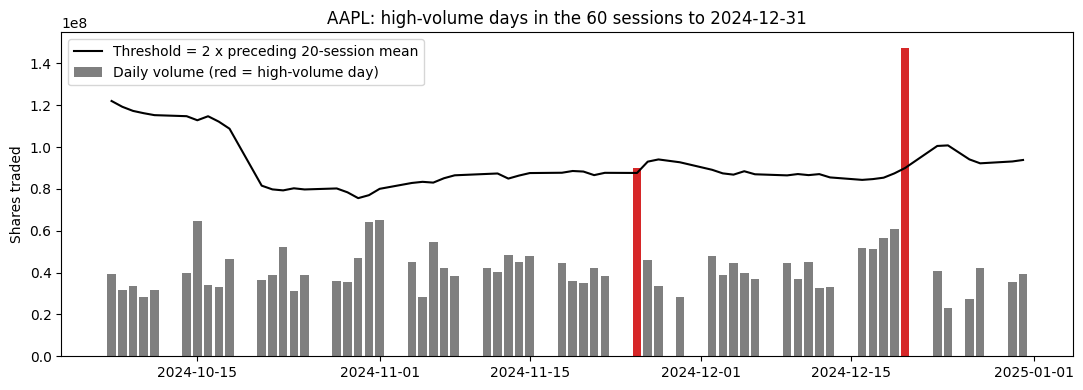

In [13]:
# ===== 1.5(b) Worked RFM example for one share =====
ex_share = chk if rfm.at[chk, 'Frequency'] > 0 else rfm[rfm['Frequency'].between(1, 3)].index[0]
ex = histories[ex_share]
win = ex.tail(RFM_WINDOW).copy()
win['Ratio'] = win['Volume'] / win['Baseline']
win['Traded_value'] = win['Close'] * win['Volume']
win.to_csv(f'{OUT_DIR}/worked_example_{ex_share}.csv')

print(f'Worked example: {ex_share} | observation date {observation_date.date()}')

last_ev = ex[ex['HighVolume']].index[-1]
row = ex.loc[last_ev]
print(f"\nRECENCY: latest high-volume day {last_ev.date()}: volume {row['Volume']:,.0f} > "
      f"2 x {row['Baseline']:,.0f} = {row['Threshold']:,.0f} (ratio {row['Volume']/row['Baseline']:.2f})")
print(f"  R = {observation_date.date()} - {last_ev.date()} = {rfm.at[ex_share, 'Recency']:.0f} calendar days")

print(f"\nFREQUENCY: qualifying days in the 60 sessions {win.index[0].date()} to {win.index[-1].date()}:")
print(win.loc[win['HighVolume'], ['Volume', 'Baseline', 'Threshold', 'Ratio']].round(2).to_string())
print(f"  F = {rfm.at[ex_share, 'Frequency']}")

print('\nMONETARY: Close x Volume, first and last 3 of 60 sessions:')
print(pd.concat([win.head(3), win.tail(3)])[['Close', 'Volume', 'Traded_value']].round(2).to_string())
print(f"  M = sum of 60 daily values = ${win['Traded_value'].sum():,.0f} "
      f"(${win['Traded_value'].sum()/1e9:.2f} bn)")
assert np.isclose(win['Traded_value'].sum(), rfm.at[ex_share, 'Monetary'])

# Figure: volume vs threshold over the window
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(win.index, win['Volume'], color=np.where(win['HighVolume'], 'tab:red', 'tab:gray'),
       label='Daily volume (red = high-volume day)')
ax.plot(win.index, win['Threshold'], color='black', label='Threshold = 2 x preceding 20-session mean')
ax.set_title(f'{ex_share}: high-volume days in the 60 sessions to {observation_date.date()}')
ax.set_ylabel('Shares traded'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/worked_example_{ex_share}.png', dpi=150); plt.show()

# Task 2: Stock Segmentation and Sensitivity Analysis

## 2.1 Feature preparation

Common share set for all clustering solutions: 486

                              min        median           max     skew  IQR_outliers  abs_z_gt_3  skew_after_log1p
Mean_Weekly_Return -4.500000e-03  2.600000e-03  1.780000e-02   0.8675          15.0         6.0               NaN
Beta                5.550000e-02  9.506000e-01  3.778600e+00   1.1036          10.0         2.0               NaN
Recency             4.000000e+00  1.100000e+01  2.220000e+02   3.6458         115.0        11.0            1.5832
Frequency           0.000000e+00  3.000000e+00  8.000000e+00   0.4247           2.0         5.0           -0.9284
Monetary            1.297483e+09  1.668382e+10  1.847697e+12  11.6838          45.0         5.0            1.0791

Most extreme shares per feature (|z|):
  Mean_Weekly_Return: SMCI (0.01777, z=+5.6), NVDA (0.01362, z=+4.1), VRT (0.01258, z=+3.7)
  Beta: CVNA (3.779, z=+6.9), XYZ (2.505, z=+3.8), COHR (2.139, z=+2.9)
  Recency: NVDA (222, z=+9.5), WEC (151, z=+6.1), COR (102,

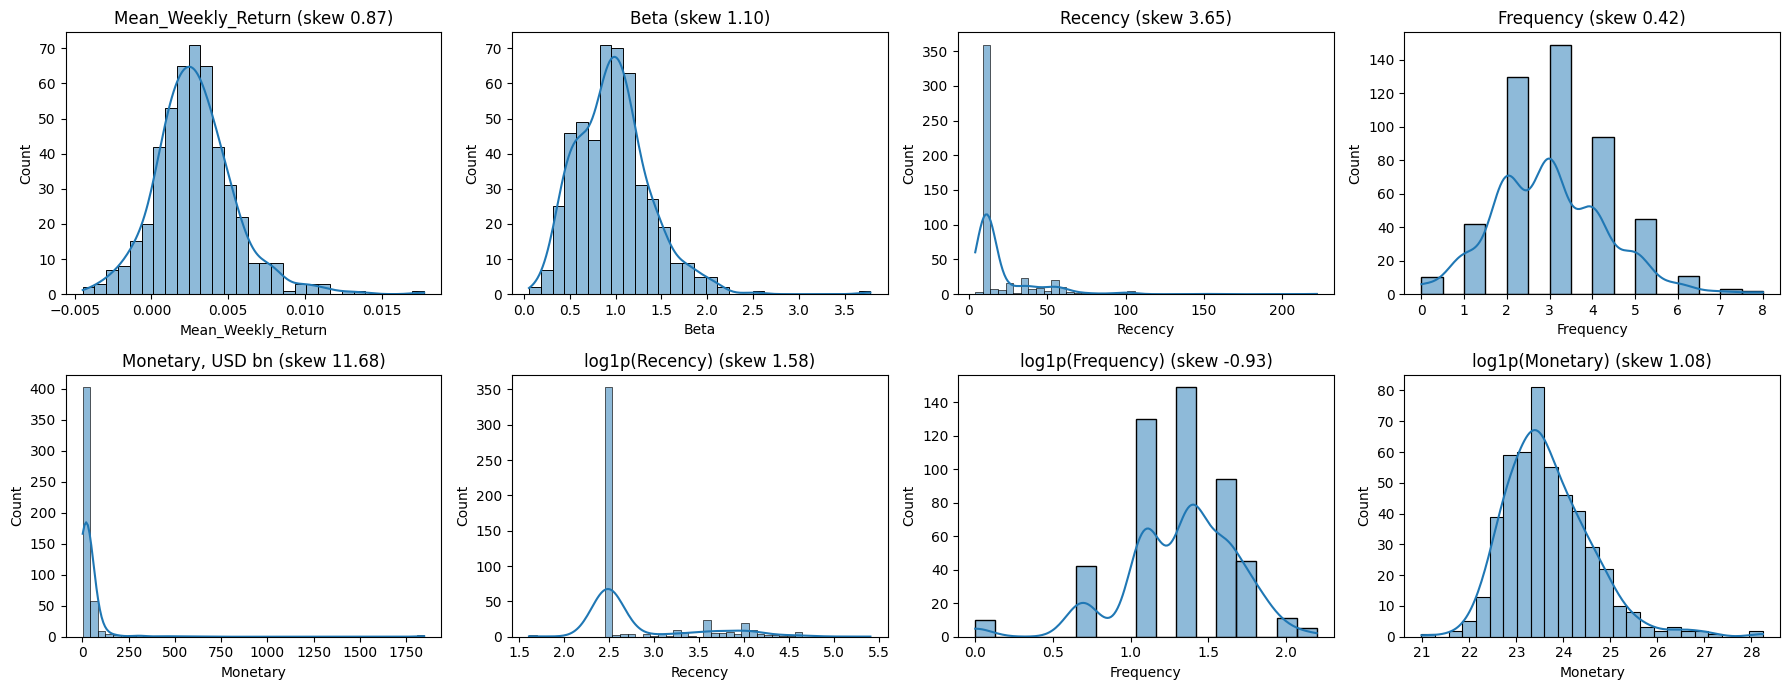


% of total variance by feature (drives Euclidean distance before scaling):
  Risk-return, raw:             {'Mean_Weekly_Return': 0.0, 'Beta': 100.0}
  RFM, raw:                     {'Recency': 0.0, 'Frequency': 0.0, 'Monetary': 100.0}
  RFM, log1p(M), unscaled:      {'Recency': 99.42, 'Frequency': 0.39, 'Monetary': 0.19}
  After StandardScaler:         every feature has variance 1 = comparable scale, NOT necessarily equal influence (correlated features can double-count one characteristic; see 2.5.1)


In [14]:
# ===== 2.1(a) Common share set and feature diagnostics (skew, outliers) =====
RISK_COLS = ['Mean_Weekly_Return', 'Beta']
RFM_COLS  = ['Recency', 'Frequency', 'Monetary']

clust = features.loc[features['In_clustering_set'],
                     RISK_COLS + RFM_COLS + ['Security', 'GICS Sector']].copy()
assert clust[RISK_COLS + RFM_COLS].notna().all().all()
print('Common share set for all clustering solutions:', len(clust))

def describe_shape(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    z = (s - s.mean()) / s.std(ddof=0)
    return pd.Series({'min': s.min(), 'median': s.median(), 'max': s.max(), 'skew': s.skew(),
                      'IQR_outliers': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                      'abs_z_gt_3': int((z.abs() > 3).sum())})

diag = clust[RISK_COLS + RFM_COLS].apply(describe_shape).T
for c in RFM_COLS:
    diag.loc[c, 'skew_after_log1p'] = np.log1p(clust[c]).skew()
print('\n', diag.round(4).to_string())
diag.to_csv(f'{OUT_DIR}/feature_skew_outliers.csv')

print('\nMost extreme shares per feature (|z|):')
for c in RISK_COLS + RFM_COLS:
    z = (clust[c] - clust[c].mean()) / clust[c].std(ddof=0)
    top = z.abs().nlargest(3).index
    print(f'  {c}: ' + ', '.join(f'{t} ({clust.at[t, c]:.4g}, z={z[t]:+.1f})' for t in top))

# Distributions (Week 2 histplot style): raw features, then log1p of the RFM features
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes[0], ['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency']):
    sns.histplot(data=clust, x=c, kde=True, ax=ax)
    ax.set_title(f'{c} (skew {clust[c].skew():.2f})')
sns.histplot(x=clust['Monetary'] / 1e9, kde=True, ax=axes[1][0])
axes[1][0].set_title(f"Monetary, USD bn (skew {clust['Monetary'].skew():.2f})")
for ax, c in zip(axes[1][1:], RFM_COLS):
    sns.histplot(x=np.log1p(clust[c]), kde=True, ax=ax)
    ax.set_title(f'log1p({c}) (skew {np.log1p(clust[c]).skew():.2f})')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/feature_distributions.png', dpi=150); plt.show()

# What Euclidean distance "sees": each feature's share of total variance
def variance_share(X):
    v = X.var(ddof=0)
    return (100 * v / v.sum()).round(2).to_dict()

tmp = clust[RFM_COLS].copy(); tmp['Monetary'] = np.log1p(tmp['Monetary'])
print('\n% of total variance by feature (drives Euclidean distance before scaling):')
print('  Risk-return, raw:            ', variance_share(clust[RISK_COLS]))
print('  RFM, raw:                    ', variance_share(clust[RFM_COLS]))
print('  RFM, log1p(M), unscaled:     ', variance_share(tmp))
print('  After StandardScaler:         every feature has variance 1 = comparable scale, NOT necessarily '
      'equal influence (correlated features can double-count one characteristic; see 2.5.1)')

In [15]:
# ===== 2.1(b) Transformations and standardisation: two separate matrices =====
from sklearn.preprocessing import StandardScaler
SKEW_RULE = 1.0      # |skew| > 1 = highly skewed (Bulmer, 1979 rule of thumb)

# Decision rule, fixed before fitting: M is log1p by the brief; R and F only if highly
# skewed AND log1p reduces the skew. Beta and mean return are never logged (slide 19).
log_decisions = {'Monetary': True}
print('Transformation decisions:')
for c in ['Recency', 'Frequency']:
    raw_s, log_s = clust[c].skew(), np.log1p(clust[c]).skew()
    log_decisions[c] = bool(abs(raw_s) > SKEW_RULE and abs(log_s) < abs(raw_s))
    print(f'  {c}: skew raw {raw_s:.2f}, after log1p {log_s:.2f} -> log1p applied: {log_decisions[c]}')
print(f"  Monetary: skew raw {clust['Monetary'].skew():.2f}, after log1p "
      f"{np.log1p(clust['Monetary']).skew():.2f} -> log1p applied: True (required by the brief)")
print('  Mean_Weekly_Return, Beta: not log-transformed (return can be negative; slide 19). Outliers retained.')

# --- Matrix A: risk and return ---
X_risk_raw = clust[RISK_COLS].copy()
scaler_risk = StandardScaler()
X_risk = pd.DataFrame(scaler_risk.fit_transform(X_risk_raw),
                      index=X_risk_raw.index, columns=RISK_COLS)

# --- Matrix B: trading activity (RFM) ---
X_rfm_t = clust[RFM_COLS].copy()
for c in RFM_COLS:
    if log_decisions[c]:
        X_rfm_t[c] = np.log1p(X_rfm_t[c])
X_rfm_t.columns = [f'log1p_{c}' if log_decisions[c] else c for c in RFM_COLS]
scaler_rfm = StandardScaler()
X_rfm = pd.DataFrame(scaler_rfm.fit_transform(X_rfm_t),
                     index=X_rfm_t.index, columns=X_rfm_t.columns)

# --- Checks (Week 2: mean 0, standard deviation 1) ---
for name, X in [('Risk-return', X_risk), ('RFM', X_rfm)]:
    print(f'\n{name}: shape {X.shape} | columns {list(X.columns)}')
    print(f'  mean {X.mean().round(2).tolist()} | std {X.std(ddof=0).round(2).tolist()}')
    print(f'  skew {X.skew().round(2).tolist()} | shares with |z|>3: {int((X.abs() > 3).any(axis=1).sum())}')

assert X_risk.index.equals(X_rfm.index) and len(X_risk) == len(clust), 'Matrices use different shares'
for X in (X_risk_raw, X_rfm_t, X_risk, X_rfm):
    assert np.isfinite(X.to_numpy(dtype=float)).all(), 'Missing or infinite values before clustering'
assert (X_risk_raw.std() > 0).all() and (X_rfm_t.std() > 0).all(), 'Constant feature: cannot standardise'
print(f'\nChecks passed: same {len(clust)} shares in both matrices, no missing/infinite values, no constant features.')
# log_decisions is reused unchanged in 2.5.2 (R and F only), so the sensitivity test changes one thing: M.

# --- Preserve every stage: original units, transformed, standardised ---
clust.to_csv(f'{OUT_DIR}/clustering_set_original_units.csv')
X_rfm_t.to_csv(f'{OUT_DIR}/matrix_rfm_transformed.csv')
X_risk.to_csv(f'{OUT_DIR}/matrix_risk_return_scaled.csv')
X_rfm.to_csv(f'{OUT_DIR}/matrix_rfm_scaled.csv')
print('Saved original, transformed and standardised matrices to', OUT_DIR)

Transformation decisions:
  Recency: skew raw 3.65, after log1p 1.58 -> log1p applied: True
  Frequency: skew raw 0.42, after log1p -0.93 -> log1p applied: False
  Monetary: skew raw 11.68, after log1p 1.08 -> log1p applied: True (required by the brief)
  Mean_Weekly_Return, Beta: not log-transformed (return can be negative; slide 19). Outliers retained.

Risk-return: shape (486, 2) | columns ['Mean_Weekly_Return', 'Beta']
  mean [0.0, 0.0] | std [1.0, 1.0]
  skew [0.87, 1.1] | shares with |z|>3: 7

RFM: shape (486, 3) | columns ['log1p_Recency', 'Frequency', 'log1p_Monetary']
  mean [0.0, -0.0, -0.0] | std [1.0, 1.0, 1.0]
  skew [1.58, 0.42, 1.08] | shares with |z|>3: 13

Checks passed: same 486 shares in both matrices, no missing/infinite values, no constant features.
Saved original, transformed and standardised matrices to outputs


## Reproducibility
### Save the live-run reference (first run only, `USE_CACHE = False`)

In [16]:
# ===== Run ONLY after the first (USE_CACHE=False) run: reference for the reproducibility check =====
if not USE_CACHE:
    features.to_csv(f'{OUT_DIR}/feature_table_live_run.csv')
    print('Live-run feature table saved. Now set USE_CACHE = True, restart, and rerun from the top.')
else:
    print('USE_CACHE = True: skipping (reference is only saved on the live run).')

Live-run feature table saved. Now set USE_CACHE = True, restart, and rerun from the top.


### Reproducibility check (second run only, `USE_CACHE = True`)

In [17]:
# ===== Verification: pickle snapshot reproduces the live run exactly =====
cols5 = ['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']

reloaded = pd.read_pickle(PKL_PATH)
assert reloaded.equals(sp500_data), 'Pickle reload differs'
assert set(fields).issubset(set(sp500_data.columns.get_level_values(0))), 'Required fields missing'
assert '^GSPC' in sp500_data['Adj Close'].columns and market['Adj Close'].notna().all()
print('1. Pickle round-trip identical | fields + ^GSPC present | sp500_data', sp500_data.shape)
print('2. data:', {f: data[f].shape for f in fields}, '| market:', market.shape)
print('3. Failed downloads logged:', acq_log['Share'].tolist())

live = pd.read_csv(f'{OUT_DIR}/feature_table_live_run.csv', index_col='Share')
assert sorted(features.index) == sorted(live.index), 'Cache run used a different share set'
max_diff = (features[cols5] - live.loc[features.index, cols5]).abs().max()
print('4. Feature table:', features.shape, '| same shares as the live run')
print('5. Max absolute difference, cache run vs live run:\n', max_diff.to_string())
assert np.allclose(features[cols5], live.loc[features.index, cols5], rtol=1e-9, atol=1e-12)
print('\nAll checks passed: the notebook rebuilds identical features from data/sp500_data.pkl.')

1. Pickle round-trip identical | fields + ^GSPC present | sp500_data (1005, 4022)
2. data: {'Close': (1005, 503), 'Adj Close': (1005, 503), 'Volume': (1005, 503), 'Dividends': (1005, 503), 'Stock Splits': (1005, 503)} | market: (1005, 3)
3. Failed downloads logged: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
4. Feature table: (486, 14) | same shares as the live run
5. Max absolute difference, cache run vs live run:
 Mean_Weekly_Return    9.931292e-17
Beta                  4.440892e-16
Recency               0.000000e+00
Frequency             0.000000e+00
Monetary              6.103516e-05

All checks passed: the notebook rebuilds identical features from data/sp500_data.pkl.


## 2.2 Agglomerative clustering (Ward linkage)
Evidence cell: the number of clusters is chosen afterwards using silhouette, cluster sizes,
merge-height gaps and original-unit profiles together (a dendrogram colour threshold alone
does not define k).


===== Ward: Risk-return matrix ['Mean_Weekly_Return', 'Beta'] =====
   silhouette  merge_gap  smallest  largest                             sizes
k                                                                            
2      0.3395      4.271        92      394                         [394, 92]
3      0.2738      4.592        92      230                    [230, 164, 92]
4      0.2821      1.541        48      182                [182, 164, 92, 48]
5      0.3041      1.068        48      182             [182, 98, 92, 66, 48]
6      0.3204      3.260         5      182          [182, 98, 87, 66, 48, 5]
7      0.3240      0.033         5      160      [160, 98, 87, 66, 48, 22, 5]
8      0.3208      2.379         5      160  [160, 98, 66, 56, 48, 31, 22, 5]
Top merge heights (last 8 merges): [23.07, 18.8, 14.21, 12.67, 11.6, 8.34, 8.31, 5.93]

===== Ward: RFM matrix ['log1p_Recency', 'Frequency', 'log1p_Monetary'] =====
   silhouette  merge_gap  smallest  largest                    

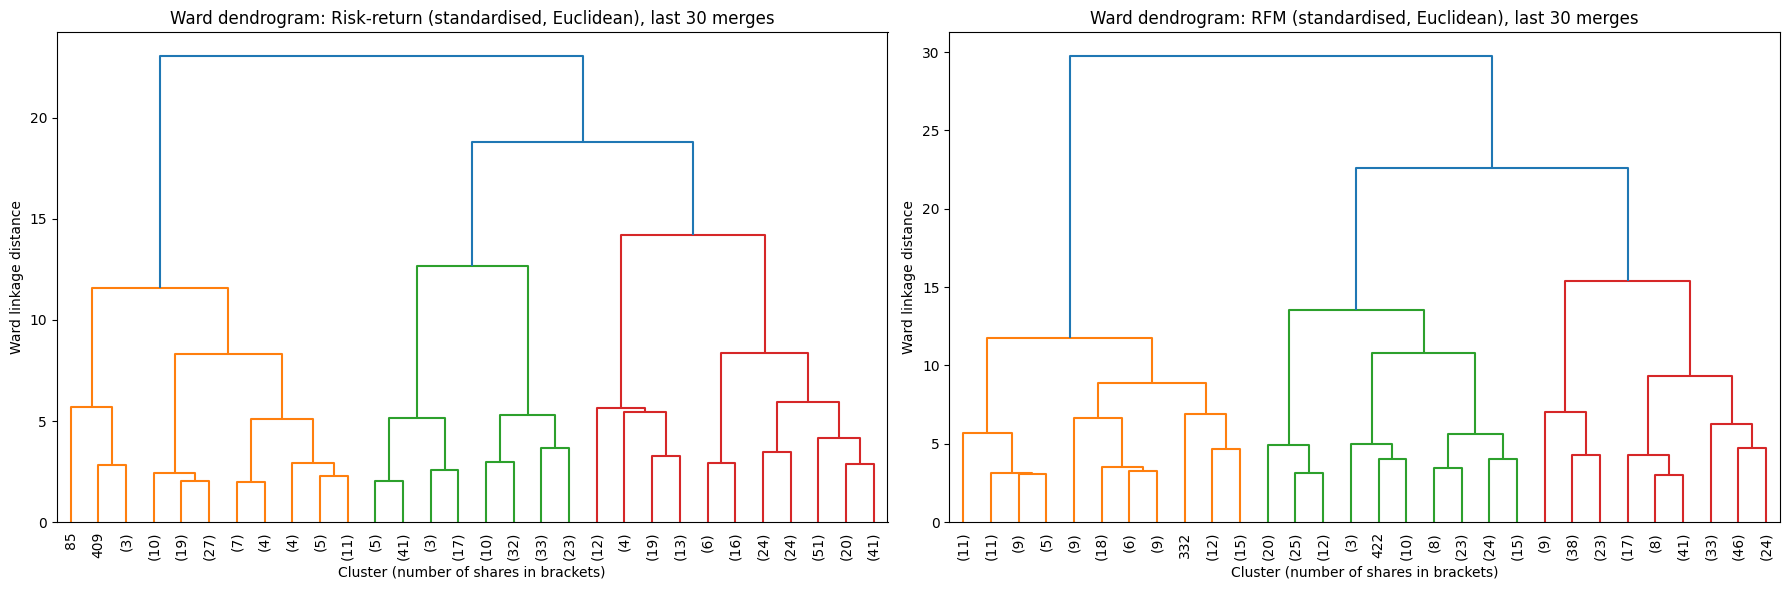

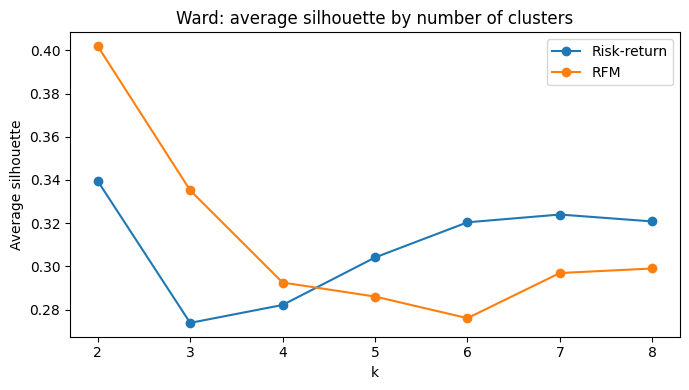


--- Ward Risk-return, k = 2: profile in original units ---
  size Mean_Weekly_Return            Beta        
                     mean  median    mean  median
1  394             0.0020  0.0021  0.8979  0.8817
2   92             0.0063  0.0055  1.2981  1.2177

--- Ward Risk-return, k = 3: profile in original units ---
  size Mean_Weekly_Return            Beta        
                     mean  median    mean  median
1  230             0.0015  0.0017  1.1096  1.0384
2  164             0.0029  0.0033  0.6012  0.5777
3   92             0.0063  0.0055  1.2981  1.2177

--- Ward Risk-return, k = 4: profile in original units ---
  size Mean_Weekly_Return            Beta        
                     mean  median    mean  median
1  182             0.0013  0.0017  0.9728  0.9644
2  164             0.0029  0.0033  0.6012  0.5777
3   48             0.0020  0.0025  1.6280  1.5139
4   92             0.0063  0.0055  1.2981  1.2177

--- Ward Risk-return, k = 5: profile in original units ---
  size Mea

In [18]:
# ===== 2.2(a) Agglomerative clustering: Ward linkage, Euclidean distance (Week 3 method) =====
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score

K_RANGE = range(2, 9)
matrices = {'Risk-return': X_risk, 'RFM': X_rfm}
orig_cols = {'Risk-return': RISK_COLS, 'RFM': RFM_COLS}
ward_Z, ward_eval, ward_labels = {}, {}, {}

def profile(labels, cols):
    """Cluster profile in ORIGINAL units (Week 2/3: groupby mean), with size; Monetary in USD bn."""
    p = clust[cols].groupby(labels).agg(['mean', 'median'])
    if 'Monetary' in cols:
        p['Monetary'] = p['Monetary'] / 1e9
    p.insert(0, 'size', pd.Series(labels).value_counts().sort_index().values)
    return p

for name, X in matrices.items():
    Z = linkage(X.to_numpy(), method='ward')     # Ward linkage uses Euclidean geometry
    ward_Z[name] = Z
    rows = []
    for k in K_RANGE:
        labels = cut_tree(Z, n_clusters=k).ravel() + 1
        assert len(np.unique(labels)) == k, 'cut_tree returned the wrong number of clusters'
        ward_labels[(name, k)] = labels
        sizes = np.bincount(labels)[1:]
        rows.append({'k': k,
                     'silhouette': round(silhouette_score(X, labels), 4),
                     'merge_gap': round(Z[-(k - 1), 2] - Z[-k, 2], 3),  # height span where the cut gives k clusters
                     'smallest': int(sizes.min()), 'largest': int(sizes.max()),
                     'sizes': sorted(sizes.tolist(), reverse=True)})
    ward_eval[name] = pd.DataFrame(rows).set_index('k')
    ward_eval[name].to_csv(f"{OUT_DIR}/ward_k_evaluation_{name.replace('-', '_')}.csv")
    print(f'\n===== Ward: {name} matrix {list(X.columns)} =====')
    print(ward_eval[name].to_string())
    print('Top merge heights (last 8 merges):', np.round(Z[-8:, 2][::-1], 2).tolist())

# --- One dendrogram per matrix (truncated to the last 30 merges for readability) ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (name, Z) in zip(axes, ward_Z.items()):
    dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True,
               leaf_rotation=90, ax=ax, color_threshold=None)
    ax.set_title(f'Ward dendrogram: {name} (standardised, Euclidean), last 30 merges')
    ax.set_xlabel('Cluster (number of shares in brackets)')
    ax.set_ylabel('Ward linkage distance')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/ward_dendrograms.png', dpi=150); plt.show()

# --- Silhouette vs k for both matrices ---
fig, ax = plt.subplots(figsize=(7, 4))
for name, ev in ward_eval.items():
    ax.plot(ev.index, ev['silhouette'], 'o-', label=name)
ax.set(title='Ward: average silhouette by number of clusters', xlabel='k', ylabel='Average silhouette')
ax.legend(); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/ward_silhouette.png', dpi=150); plt.show()

# --- Original-unit profiles for k = 2 to 6 (interpretability evidence) ---
for name in matrices:
    for k in range(2, 7):
        print(f'\n--- Ward {name}, k = {k}: profile in original units ---')
        print(profile(ward_labels[(name, k)], orig_cols[name]).round(4).to_string())